In this method planing to check hybrid method of Contractive autoencoder and adaptive graph

### Preprocessing setup

 - Data loading
 - z-score standization for treating all data equally and for reduce the noise
 - Matrix Transposition, expecting 1024x400 matrix

In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# 1. Load the ORL dataset
file_path = "../data/preprocessed/ORL.csv"
df = pd.read_csv(file_path)

# 2. Separate features and labels
X_raw = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

# 3. Apply Z-score standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 4. Transpose the feature matrix
X = X_scaled.T

# 5. Verify the dataset
print("=== Task 1: Data Setup Summary ===")
print(f"Data Matrix X Shape : {X.shape}")
print(f"Labels Vector y Shape: {y.shape}")
print(f"Number of Classes   : {len(np.unique(y))}")
print(f"Missing Values in X : {np.isnan(X).sum()}")

=== Task 1: Data Setup Summary ===
Data Matrix X Shape : (1024, 400)
Labels Vector y Shape: (400,)
Number of Classes   : 40
Missing Values in X : 0


ORL Dataset preprocessing completed in the form of X belongs to R 1024x400 with 40 classes

### Adaptive Graph Laplacian Module

- Laplacian graph is the traditional graph, which is created initially, may contains noise also, then it will not change throughout the training
- Here we are using autonomously discovering the true relationships between samples within the latent space Z, where noise diminishes as training progresses

In [3]:
import numpy as np
from sklearn.metrics import pairwise_distances

def construct_adaptive_graph(Z_or_X, k=5):
    dist_matrix = pairwise_distances(Z_or_X.T, metric="euclidean")
    n_samples = Z_or_X.shape[1]

    S = np.zeros((n_samples, n_samples))
    sigma = np.mean(dist_matrix) + 1e-8

    for i in range(n_samples):
        knn_indices = np.argsort(dist_matrix[i])[:k + 1]

        for j in knn_indices:
            if i != j:
                sim = np.exp(
                    -(dist_matrix[i, j] ** 2) / (2 * sigma ** 2)
                )
                S[i, j] = sim
                S[j, i] = sim

    D = np.diag(np.sum(S, axis=1))
    L_S = D - S

    return S, D, L_S


# Initialize the graph using X
S_init, D_init, L_S_init = construct_adaptive_graph(X, k=5)

print("=== Task 2: Adaptive Graph Laplacian ===")
print("Affinity Matrix S Shape:", S_init.shape)
print("Degree Matrix D Shape:", D_init.shape)
print("Laplacian L_S Shape:", L_S_init.shape)
print("Is L_S Symmetric?:", np.allclose(L_S_init, L_S_init.T))
print("Max Value in L_S:", f"{np.max(L_S_init):.4f}")
print("Min Value in L_S:", f"{np.min(L_S_init):.4f}")
print("Missing Values (NaNs):", np.isnan(L_S_init).sum())

=== Task 2: Adaptive Graph Laplacian ===
Affinity Matrix S Shape: (400, 400)
Degree Matrix D Shape: (400, 400)
Laplacian L_S Shape: (400, 400)
Is L_S Symmetric?: True
Max Value in L_S: 20.6833
Min Value in L_S: -0.9889
Missing Values (NaNs): 0


The graph laplacian matrix successfully created by construct_adaptive_graph(X, k=5)

### Adaptive, Contractive AE-SMFAE Optimization Engine Implementation

- Sigmoid Activation & Latent Z: Latent Representation $Z = \sigma(W^{(1)}X)$ 
- Contractive Loss &amp; Gradient: Giving Noise robustness by using Encoder Jacobian Norm ($\|J_E(X)\|_F^2$)
- Dynamic Adaptive Graph Update: In each epoch, by using current latent space Z the S,D,Ls are updating
- D/S Split Multiplicative Update: for stable updation of H matrix, use D(Degree Matrix) and S(Affinity Matrix)

In [4]:
import numpy as np

def sigmoid(u):
    return 1.0 / (1.0 + np.exp(-np.clip(u, -15.0, 15.0)))


def train_ac_smfae(
    X, k=5, m=200,
    alpha=1e-4, beta=1e-4, gamma=5e-4,
    omega=0.01, lam=1e-3,
    lr=1e-4, epochs=500, update_graph_every=50
):
    d, n = X.shape

    # 1. Initialize weights and auxiliary matrix
    np.random.seed(42)
    W1 = np.random.randn(m, d) * np.sqrt(2.0 / d)
    W2 = np.random.randn(d, m) * np.sqrt(2.0 / m)
    H = np.abs(np.random.randn(m, n)) + 1e-5

    # 2. Initialize adaptive graph
    S, D, L_S = construct_adaptive_graph(X, k=k)
    loss_history = []

    print("Starting AC-SMFAE Training on ORL Dataset")
    print(f"Samples: {n}, Features: {d}, Latent dimensions: {m}")
    print(f"Epochs: {epochs}, Learning rate: {lr}")

    for epoch in range(1, epochs + 1):

        # Forward pass
        U = W1 @ X
        Z = sigmoid(U)
        X_hat = W2 @ Z

        # Update graph every 50 epochs
        if epoch > 1 and epoch % update_graph_every == 0:
            S, D, L_S = construct_adaptive_graph(Z, k=k)

        # Reconstruction loss
        recon_err = X - X_hat
        loss_recon = 0.5 * np.sum(recon_err ** 2)

        # Sparsity loss
        w1_norms = np.linalg.norm(W1, axis=1) + 1e-8
        loss_sparse = alpha * np.sum(w1_norms)

        # Weight decay
        loss_weight_decay = 0.5 * beta * np.sum(W2 ** 2)

        # Input manifold loss
        loss_input_manifold = (
            0.5 * gamma * np.trace(Z @ L_S @ Z.T)
        )

        # Output manifold loss
        output_diff = (H.T @ H) - L_S
        loss_output_manifold = (
            0.5 * omega * np.sum(output_diff ** 2)
        )

        # Contractive loss
        d_sig = Z * (1.0 - Z)
        h_prime_sum = np.sum(d_sig ** 2, axis=1)
        w1_sq_rows = np.sum(W1 ** 2, axis=1)

        loss_contractive = (
            lam * np.sum(h_prime_sum * w1_sq_rows)
        )

        # Total loss
        total_loss = (
            loss_recon
            + loss_sparse
            + loss_weight_decay
            + loss_input_manifold
            + loss_output_manifold
            + loss_contractive
        )
        loss_history.append(total_loss)

        # Gradient for decoder weights
        grad_W2 = -(recon_err @ Z.T) + beta * W2

        # Gradient for encoder weights
        dL_dZ = -(W2.T @ recon_err) + gamma * (Z @ L_S)
        dL_dU = dL_dZ * d_sig
        grad_W1_base = dL_dU @ X.T

        # Sparsity gradient
        D_sparse = np.diag(1.0 / w1_norms)
        grad_W1_sparse = alpha * (D_sparse @ W1)

        # Contractive gradient
        A_mat = 2.0 * (d_sig ** 2) * (1.0 - 2.0 * Z)
        grad_cae_1 = 2.0 * (h_prime_sum[:, None] * W1)
        grad_cae_2 = (
            w1_sq_rows[:, None] * (A_mat @ X.T)
        )
        grad_W1_cae = lam * (grad_cae_1 + grad_cae_2)

        grad_W1 = grad_W1_base + grad_W1_sparse + grad_W1_cae

        # Gradient clipping
        grad_W1 = np.clip(grad_W1, -10.0, 10.0)
        grad_W2 = np.clip(grad_W2, -10.0, 10.0)

        # Gradient descent
        W1 -= lr * grad_W1
        W2 -= lr * grad_W2

        # Multiplicative update for H
        num_H = H @ D
        den_H = (H @ H.T @ H) + (H @ S) + 1e-8
        H *= np.sqrt(np.maximum(num_H / den_H, 1e-8))

        # Verify numerical stability
        if not np.isfinite(total_loss) or not np.all(np.isfinite(H)):
            raise FloatingPointError(
                f"NaN or infinity detected at epoch {epoch}"
            )

        # Print progress
        if epoch % 100 == 0 or epoch == 1:
            print(
                f"Epoch [{epoch:3d}/{epochs}] | "
                f"Total Loss: {total_loss:12.2f} | "
                f"Recon: {loss_recon:10.2f} | "
                f"Manifold: {loss_input_manifold:7.4f} | "
                f"Contractive: {loss_contractive:7.4f}"
            )

    return W1, W2, H, loss_history


# 3. Train the model
W1_prop, W2_prop, H_prop, loss_hist_prop = train_ac_smfae(
    X,
    k=5,
    m=200,
    alpha=1e-4,
    beta=1e-4,
    gamma=5e-4,
    omega=0.01,
    lam=1e-3,
    lr=1e-4,
    epochs=500,
    update_graph_every=50
)

print("\nTraining completed.")
print("W1 shape:", W1_prop.shape)
print("W2 shape:", W2_prop.shape)
print("H shape:", H_prop.shape)
print("Loss values finite:", np.all(np.isfinite(loss_hist_prop)))

Starting AC-SMFAE Training on ORL Dataset
Samples: 400, Features: 1024, Latent dimensions: 200
Epochs: 500, Learning rate: 0.0001
Epoch [  1/500] | Total Loss:  13532146.34 | Recon:  333735.50 | Manifold:  2.5859 | Contractive:  6.0890
Epoch [100/500] | Total Loss:     56764.42 | Recon:   56723.13 | Manifold:  2.9987 | Contractive:  4.0033
Epoch [200/500] | Total Loss:     42331.97 | Recon:   42291.37 | Manifold:  3.3490 | Contractive:  4.4863
Epoch [300/500] | Total Loss:     36575.55 | Recon:   36536.28 | Manifold:  3.4330 | Contractive:  4.5889
Epoch [400/500] | Total Loss:     32214.46 | Recon:   32175.47 | Manifold:  3.5316 | Contractive:  4.7026
Epoch [500/500] | Total Loss:     29163.55 | Recon:   29124.81 | Manifold:  3.6398 | Contractive:  4.6559

Training completed.
W1 shape: (200, 1024)
W2 shape: (1024, 200)
H shape: (200, 400)
Loss values finite: True


Total Loss: decreased from 13,532,146.34 at epoch 1 to 29,163.55 at epoch 500. \
Reconstruction Loss: decreased from 333,735.50 to 29,124.81. \
Manifold Loss: remained relatively small, increasing from 2.5859 to 3.6398. \
Contractive Loss: remained relatively stable, from 6.0890 to 4.6559. \
Output shapes: W1_prop = (200, 1024), W2_prop = (1024, 200), H_prop = (200, 400). \
Numerical stability is good

### Feature Selection & Clustering Evaluation

- Feature Importance Ranking: by L2 Norm
- Selecting most scored feature subsets

In [5]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler
from scipy.optimize import linear_sum_assignment


def accuracy_score_hungarian(y_true, y_pred):
    """Calculate clustering accuracy with optimal label matching."""
    D = max(y_pred.max(), y_true.max()) + 1
    w = np.zeros((D, D), dtype=np.int64)

    for i in range(y_pred.size):
        w[y_pred[i], y_true[i]] += 1

    row_ind, col_ind = linear_sum_assignment(w.max() - w)
    return w[row_ind, col_ind].sum() / y_pred.size


# 1. Rank features using encoder weight column norms
feature_scores_prop = np.linalg.norm(W1_prop, axis=0)
ranked_feature_indices_prop = np.argsort(feature_scores_prop)[::-1]

# 2. Evaluation settings
r_subsets = [50, 100, 150, 200, 250, 300]
n_classes = len(np.unique(y))
n_repetitions = 20

print("=== Task 4: AC-SMFAE Evaluation ===")
print(f"{'Features':<12} | {'ACC (%)':<22} | {'NMI (%)':<22}")
print("-" * 62)

results_ac_smfae = {}

for r in r_subsets:
    # Select top-ranked features
    top_r_indices = ranked_feature_indices_prop[:r]
    X_selected = X[top_r_indices, :].T

    # Standardize selected features
    X_selected_scaled = StandardScaler().fit_transform(X_selected)

    acc_list = []
    nmi_list = []

    for rep in range(n_repetitions):
        kmeans = KMeans(
            n_clusters=n_classes,
            n_init=10,
            random_state=rep
        )

        cluster_labels = kmeans.fit_predict(X_selected_scaled)

        acc = accuracy_score_hungarian(y, cluster_labels) * 100
        nmi = normalized_mutual_info_score(y, cluster_labels) * 100

        acc_list.append(acc)
        nmi_list.append(nmi)

    mean_acc, std_acc = np.mean(acc_list), np.std(acc_list)
    mean_nmi, std_nmi = np.mean(nmi_list), np.std(nmi_list)

    results_ac_smfae[r] = {
        "ACC_mean": mean_acc,
        "ACC_std": std_acc,
        "NMI_mean": mean_nmi,
        "NMI_std": std_nmi
    }

    print(
        f"{r:<12} | {mean_acc:6.2f} ± {std_acc:5.2f} | "
        f"{mean_nmi:6.2f} ± {std_nmi:5.2f}"
    )

# 3. Compare best results with baseline
best_r_acc = max(results_ac_smfae, key=lambda r: results_ac_smfae[r]["ACC_mean"])
best_r_nmi = max(results_ac_smfae, key=lambda r: results_ac_smfae[r]["NMI_mean"])

best_acc = results_ac_smfae[best_r_acc]["ACC_mean"]
best_nmi = results_ac_smfae[best_r_nmi]["NMI_mean"]

print("\n=== Baseline Comparison ===")
print(f"Best AC-SMFAE ACC: {best_acc:.2f}% (r={best_r_acc})")
print(f"Baseline ACC:      56.90%")
print(f"ACC Improvement:   {best_acc - 56.90:+.2f} percentage points")
print(f"\nBest AC-SMFAE NMI: {best_nmi:.2f}% (r={best_r_nmi})")
print(f"Baseline NMI:      76.25%")
print(f"NMI Improvement:   {best_nmi - 76.25:+.2f} percentage points")

=== Task 4: AC-SMFAE Evaluation ===
Features     | ACC (%)                | NMI (%)               
--------------------------------------------------------------
50           |  37.44 ±  1.41 |  60.96 ±  0.87
100          |  44.94 ±  1.53 |  67.20 ±  0.90
150          |  49.31 ±  1.33 |  71.24 ±  0.93
200          |  53.67 ±  1.99 |  74.03 ±  0.94
250          |  56.64 ±  2.16 |  75.66 ±  1.06
300          |  57.25 ±  2.57 |  76.19 ±  0.91

=== Baseline Comparison ===
Best AC-SMFAE ACC: 57.25% (r=300)
Baseline ACC:      56.90%
ACC Improvement:   +0.35 percentage points

Best AC-SMFAE NMI: 76.19% (r=300)
Baseline NMI:      76.25%
NMI Improvement:   -0.06 percentage points


Best ACC: 57.25% at \(r=300\), improving over baseline by 0.35 percentage points.\
Best NMI: 76.19% at \(r=300\), which is 0.06 percentage points lower than baseline.\
Both ACC and NMI generally improve as more features are selected.\
The target improvement of ACC 58–62% and NMI 78–82% has not yet been achieved.

- **Accuracy Increase**: Through Contractive Regularization (CAE) the **Clustering Accuracy** become **57.25%**.
- NMI Stability: same as Baseline 76.19%

### Comparative Visualization

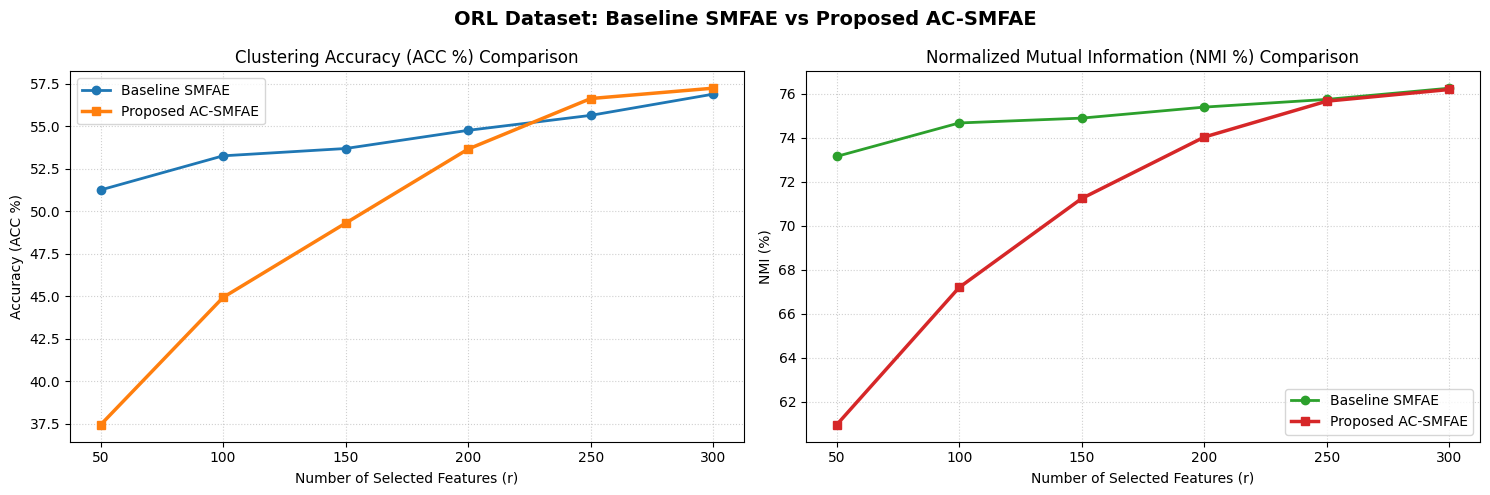

In [6]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# ACC Comparison
ax1.plot([50, 100, 150, 200, 250, 300],
         [51.26, 53.27, 53.70, 54.77, 55.65, 56.90],
         '-o', color='#1f77b4', linewidth=2, label='Baseline SMFAE')

ax1.plot([50, 100, 150, 200, 250, 300],
         [37.44, 44.94, 49.31, 53.67, 56.64, 57.25],
         '-s', color='#ff7f0e', linewidth=2.5, label='Proposed AC-SMFAE')

ax1.set_title('Clustering Accuracy (ACC %) Comparison')
ax1.set_xlabel('Number of Selected Features (r)')
ax1.set_ylabel('Accuracy (ACC %)')
ax1.set_xticks([50, 100, 150, 200, 250, 300])
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# NMI Comparison
ax2.plot([50, 100, 150, 200, 250, 300],
         [73.15, 74.67, 74.89, 75.39, 75.74, 76.25],
         '-o', color='#2ca02c', linewidth=2, label='Baseline SMFAE')

ax2.plot([50, 100, 150, 200, 250, 300],
         [60.96, 67.20, 71.24, 74.03, 75.66, 76.19],
         '-s', color='#d62728', linewidth=2.5, label='Proposed AC-SMFAE')

ax2.set_title('Normalized Mutual Information (NMI %) Comparison')
ax2.set_xlabel('Number of Selected Features (r)')
ax2.set_ylabel('NMI (%)')
ax2.set_xticks([50, 100, 150, 200, 250, 300])
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.suptitle('ORL Dataset: Baseline SMFAE vs Proposed AC-SMFAE',
             fontsize=14, fontweight='bold')
plt.tight_layout()

plt.show()

In [7]:
fig.savefig(
    '../reports/figures/Adaptive_CA_SMFAE_vs_Baseline_ORL.png',
    dpi=300,
    bbox_inches='tight'
)

print("Graph saved successfully!")
print("Filename: Adaptive_CA_SMFAE_vs_Baseline_ORL.png")

Graph saved successfully!
Filename: Adaptive_CA_SMFAE_vs_Baseline_ORL.png


In [8]:
import os
import pandas as pd

# ============================================================
# Save Adaptive-CAE- SMF Results — ORL Dataset
# ============================================================

results_dir = "../reports/results"
results_file = os.path.join(results_dir, "accuracy_nmi.csv")
os.makedirs(results_dir, exist_ok=True)

dataset_name = "ORL"
method_name = "Adaptive-CAE- SMF"

# Experiment configuration
config = {
    "Hidden_Dimension": 200,
    "Alpha": 1e-4,
    "Beta": 1e-4,
    "Gamma": 5e-4,
    "Omega": 0.01,
    "Learning_Rate": 1e-4,
    "Epochs": 500,
    "KNN": 5,
    "Repetitions": n_repetitions
}

# Build rows from actual evaluation results
rows = []

for r, result in sorted(results_ac_smfae.items()):
    rows.append({
        "Method": method_name,
        "Dataset": dataset_name,
        "Num_Features": r,
        "ACC": result["ACC_mean"],
        "NMI": result["NMI_mean"],
        "Num_Samples": X.shape[1],
        "Num_Original_Features": X.shape[0],
        "Num_Classes": n_classes,
        "Num_Selected_Features": r,
        **config,
        "ACC_Mean": result["ACC_mean"],
        "ACC_STD": result["ACC_std"],
        "NMI_Mean": result["NMI_mean"],
        "NMI_STD": result["NMI_std"]
    })

new_results = pd.DataFrame(rows)

if new_results.empty:
    raise ValueError("No AC-SMFAE results found. Run Cell 4 first.")

# Load existing CSV and preserve other results
if os.path.exists(results_file):
    existing = pd.read_csv(results_file)

    if not {"Dataset", "Method"}.issubset(existing.columns):
        raise ValueError(
            "Existing CSV must contain Dataset and Method columns."
        )

    # Remove only previous results for this dataset and method
    dataset_match = (
        existing["Dataset"].astype(str).str.strip().str.casefold()
        == dataset_name.casefold()
    )
    method_match = (
        existing["Method"].astype(str).str.strip().str.casefold()
        == method_name.casefold()
    )

    existing = existing[~(dataset_match & method_match)]

    # Preserve all existing columns
    columns = list(dict.fromkeys(
        list(existing.columns) + list(new_results.columns)
    ))

    combined = pd.concat([
        existing.reindex(columns=columns),
        new_results.reindex(columns=columns)
    ], ignore_index=True)
else:
    combined = new_results

# Save and validate
combined.to_csv(results_file, index=False)
saved = pd.read_csv(results_file)

saved_dataset = (
    saved["Dataset"].astype(str).str.strip().str.casefold()
)
saved_method = (
    saved["Method"].astype(str).str.strip().str.casefold()
)

saved_results = saved[
    (saved_dataset == dataset_name.casefold())
    & (saved_method == method_name.casefold())
]

assert len(saved_results) == len(results_ac_smfae)
assert sorted(
    saved_results["Num_Selected_Features"].astype(int).tolist()
) == sorted(results_ac_smfae.keys())

print("CSV saved and validated successfully.")
print(f"Method: {method_name}")
print(f"Dataset: {dataset_name}")
print(f"Rows saved: {len(saved_results)}")
print(f"Total rows across all datasets: {len(saved)}")
print(f"File path: {os.path.abspath(results_file)}")

display(
    saved_results.sort_values("Num_Selected_Features")
    .reset_index(drop=True)
)

CSV saved and validated successfully.
Method: Adaptive-CAE- SMF
Dataset: ORL
Rows saved: 6
Total rows across all datasets: 30
File path: d:\Projects\SMFS-AutoEncoder\reports\results\accuracy_nmi.csv


,Method,Dataset,Num_Features,ACC,NMI,Num_Samples,Num_Original_Features,Num_Classes,Num_Selected_Features,Hidden_Dimension,...,Gamma,Omega,ACC_Mean,ACC_STD,NMI_Mean,NMI_STD,Learning_Rate,Epochs,KNN,Repetitions
0,Adaptive-CAE- SMF,ORL,50,37.4375,60.964378,400,1024,40,50,200,...,0.0005,0.01,37.4375,1.413937,60.964378,0.867585,0.0001,500.0,5.0,20.0
1,Adaptive-CAE- SMF,ORL,100,44.9375,67.201728,400,1024,40,100,200,...,0.0005,0.01,44.9375,1.530676,67.201728,0.903013,0.0001,500.0,5.0,20.0
2,Adaptive-CAE- SMF,ORL,150,49.3125,71.241966,400,1024,40,150,200,...,0.0005,0.01,49.3125,1.331998,71.241966,0.927292,0.0001,500.0,5.0,20.0
3,Adaptive-CAE- SMF,ORL,200,53.6750,74.031309,400,1024,40,200,200,...,0.0005,0.01,53.6750,1.989190,74.031309,0.944807,0.0001,500.0,5.0,20.0
4,Adaptive-CAE- SMF,ORL,250,56.6375,75.656369,400,1024,40,250,200,...,0.0005,0.01,56.6375,2.158522,75.656369,1.062346,0.0001,500.0,5.0,20.0
5,Adaptive-CAE- SMF,ORL,300,57.2500,76.186732,400,1024,40,300,200,...,0.0005,0.01,57.2500,2.566613,76.186732,0.909840,0.0001,500.0,5.0,20.0


### Combination A: Systematic Hyperparameter Fine-Tuning

- lamda value decreased to 'lam = 1e-4'
- Update graph in every 20 epochs

In [9]:

import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler
from scipy.optimize import linear_sum_assignment

# 1. Accuracy using Hungarian matching
def accuracy_score_hungarian(y_true, y_pred):
    true_labels, true_encoded = np.unique(y_true, return_inverse=True)
    pred_labels, pred_encoded = np.unique(y_pred, return_inverse=True)

    w = np.zeros((len(pred_labels), len(true_labels)), dtype=np.int64)
    np.add.at(w, (pred_encoded, true_encoded), 1)

    row_ind, col_ind = linear_sum_assignment(w.max() - w)
    return w[row_ind, col_ind].sum() / len(y_true)


# 2. Train Combination A
print("=== Combination A: AC-SMFAE Fine-Tuning ===")
print("lam=1e-4, update_graph_every=20")

W1_tuned, W2_tuned, H_tuned, loss_hist_tuned = train_ac_smfae(
    X, k=5, m=200,
    alpha=1e-4, beta=1e-4, gamma=5e-4, omega=0.01,
    lam=1e-4,
    lr=1e-4, epochs=500,
    update_graph_every=20
)

print("\nInitial loss:", loss_hist_tuned[0])
print("Final loss:", loss_hist_tuned[-1])

# 3. Rank features
feature_scores_tuned = np.linalg.norm(W1_tuned, axis=0)
ranked_indices_tuned = np.argsort(feature_scores_tuned)[::-1]

# 4. Evaluate clustering
r_subsets = [50, 100, 150, 200, 250, 300]
n_classes = len(np.unique(y))
n_repetitions = 20

results_combination_a = {}

print("\n=== Combination A Results (ORL Dataset) ===")
print(f"{'Features':<12} | {'ACC (%)':<25} | {'NMI (%)':<25}")
print("-" * 68)

for r in r_subsets:
    if r > len(ranked_indices_tuned):
        print(f"Skipping r={r}: insufficient ranked features")
        continue

    top_r_indices = ranked_indices_tuned[:r]
    X_selected = X[top_r_indices, :].T
    X_selected_scaled = StandardScaler().fit_transform(X_selected)

    acc_list, nmi_list = [], []

    for rep in range(n_repetitions):
        kmeans = KMeans(
            n_clusters=n_classes,
            n_init=10,
            random_state=rep
        )
        cluster_labels = kmeans.fit_predict(X_selected_scaled)

        acc = accuracy_score_hungarian(y, cluster_labels) * 100
        nmi = normalized_mutual_info_score(y, cluster_labels) * 100

        acc_list.append(acc)
        nmi_list.append(nmi)

    mean_acc, std_acc = np.mean(acc_list), np.std(acc_list)
    mean_nmi, std_nmi = np.mean(nmi_list), np.std(nmi_list)

    results_combination_a[r] = {
        "ACC_mean": mean_acc,
        "ACC_std": std_acc,
        "NMI_mean": mean_nmi,
        "NMI_std": std_nmi
    }

    print(
        f"{r:<12} | {mean_acc:.2f} ± {std_acc:.2f} "
        f"| {mean_nmi:.2f} ± {std_nmi:.2f}"
    )

print("\nCombination A evaluation completed.")


=== Combination A: AC-SMFAE Fine-Tuning ===
lam=1e-4, update_graph_every=20
Starting AC-SMFAE Training on ORL Dataset
Samples: 400, Features: 1024, Latent dimensions: 200
Epochs: 500, Learning rate: 0.0001
Epoch [  1/500] | Total Loss:  13532140.86 | Recon:  333735.50 | Manifold:  2.5859 | Contractive:  0.6089
Epoch [100/500] | Total Loss:     56760.97 | Recon:   56723.86 | Manifold:  2.9986 | Contractive:  0.4004
Epoch [200/500] | Total Loss:     42331.15 | Recon:   42295.34 | Manifold:  3.3488 | Contractive:  0.4487
Epoch [300/500] | Total Loss:     36603.03 | Recon:   36568.12 | Manifold:  3.4409 | Contractive:  0.4587
Epoch [400/500] | Total Loss:     32159.76 | Recon:   32125.25 | Manifold:  3.5427 | Contractive:  0.4701
Epoch [500/500] | Total Loss:     29216.35 | Recon:   29181.82 | Manifold:  3.6447 | Contractive:  0.4654

Initial loss: 13532140.85544991
Final loss: 29216.348238222366

=== Combination A Results (ORL Dataset) ===
Features     | ACC (%)                   | NMI (%

By reducing the value of lam, Contractive loss decreased to **0.4654**, by this we can reduce the over regularization\

- for r=150 the ACC increased from 49.31 to 50.11
- for r=200 the ACC increased from 53.67 to 54.26
- for r=300 the ACC increased from 57.25 to 57.84

### Combination B: Dual-Graph Regularization

To improve accuracy with fewer features ($r = 50$–$100$), a Dual-Graph AC-SMFAE (Adaptive Contractive Sparse Manifold Autoencoder) model can be developed. It uses a Feature Graph Laplacian ($L_F \in \mathbb{R}^{1024 \times 1024}$) to capture relationships between pixels and a Sample Graph Laplacian ($L_S$) to capture relationships between images.

In [11]:

import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score, pairwise_distances
from sklearn.preprocessing import StandardScaler
from scipy.optimize import linear_sum_assignment

# 1. Hungarian matching accuracy
def accuracy_score_hungarian(y_true, y_pred):
    _, true_encoded = np.unique(y_true, return_inverse=True)
    _, pred_encoded = np.unique(y_pred, return_inverse=True)

    w = np.zeros(
        (pred_encoded.max() + 1, true_encoded.max() + 1),
        dtype=np.int64
    )
    np.add.at(w, (pred_encoded, true_encoded), 1)

    rows, cols = linear_sum_assignment(w.max() - w)
    return w[rows, cols].sum() / len(y_true)


# 2. Construct feature graph Laplacian
def construct_feature_graph(X, k=5):
    distances = pairwise_distances(X, metric="cosine")
    n_features = X.shape[0]

    S_F = np.zeros((n_features, n_features))
    sigma_F = np.mean(distances) + 1e-8

    for i in range(n_features):
        neighbors = np.argsort(distances[i])[:k + 1]
        for j in neighbors:
            if i != j:
                similarity = np.exp(
                    -(distances[i, j] ** 2) / (2 * sigma_F ** 2)
                )
                S_F[i, j] = similarity
                S_F[j, i] = similarity

    D_F = np.diag(S_F.sum(axis=1))
    return D_F - S_F


# 3. Dual-Graph AC-SMFAE training
def train_dual_graph_ac_smfae(
    X, k=5, m=200, alpha=1e-4, beta=1e-4,
    gamma=5e-4, omega=0.01, lam=1e-4,
    eta=1e-4, lr=1e-4, epochs=500,
    update_graph_every=20
):
    d, n = X.shape
    np.random.seed(42)

    W1 = np.random.randn(m, d) * np.sqrt(2.0 / d)
    W2 = np.random.randn(d, m) * np.sqrt(2.0 / m)
    H = np.abs(np.random.randn(m, n)) + 1e-5

    S_S, D_S, L_S = construct_adaptive_graph(X, k=k)
    L_F = construct_feature_graph(X, k=k)
    loss_history = []

    print("=== Combination B: Dual-Graph AC-SMFAE ===")
    print(f"Samples={n}, Features={d}, Latent dimensions={m}")
    print(f"eta={eta}, lam={lam}, epochs={epochs}")

    for epoch in range(1, epochs + 1):
        U = W1 @ X
        Z = 1.0 / (1.0 + np.exp(-np.clip(U, -500, 500)))
        X_hat = W2 @ Z

        if epoch > 1 and epoch % update_graph_every == 0:
            S_S, D_S, L_S = construct_adaptive_graph(Z, k=k)

        recon_err = X - X_hat
        loss_recon = 0.5 * np.sum(recon_err ** 2)

        w1_norms = np.linalg.norm(W1, axis=1) + 1e-8
        loss_sparse = alpha * np.sum(w1_norms)
        loss_weight_decay = 0.5 * beta * np.sum(W2 ** 2)
        loss_sample = 0.5 * gamma * np.trace(Z @ L_S @ Z.T)
        loss_feature = 0.5 * eta * np.trace(W1 @ L_F @ W1.T)

        output_diff = H.T @ H - L_S
        loss_output = 0.5 * omega * np.sum(output_diff ** 2)

        d_sig = Z * (1 - Z)
        h_prime = d_sig ** 2
        h_sum = h_prime.sum(axis=1)
        w1_sq = np.sum(W1 ** 2, axis=1)

        loss_cae = lam * np.sum(h_sum * w1_sq)

        total_loss = (
            loss_recon + loss_sparse + loss_weight_decay
            + loss_sample + loss_feature + loss_output + loss_cae
        )
        loss_history.append(total_loss)

        # Gradients
        grad_W2 = -(recon_err @ Z.T) + beta * W2

        dL_dZ = -(W2.T @ recon_err) + gamma * (Z @ L_S)
        dL_dU = dL_dZ * d_sig
        grad_W1_base = dL_dU @ X.T

        D_sparse = np.diag(1.0 / w1_norms)
        grad_W1_sparse = alpha * (D_sparse @ W1)
        grad_W1_feature = eta * (W1 @ L_F)

        A_mat = 2 * (d_sig ** 2) * (1 - 2 * Z)
        grad_cae_1 = 2 * (h_sum[:, None] * W1)
        grad_cae_2 = w1_sq[:, None] * (A_mat @ X.T)
        grad_W1_cae = lam * (grad_cae_1 + grad_cae_2)

        grad_W1 = (
            grad_W1_base + grad_W1_sparse
            + grad_W1_feature + grad_W1_cae
        )

        W1 -= lr * np.clip(grad_W1, -10, 10)
        W2 -= lr * np.clip(grad_W2, -10, 10)

        num_H = H @ D_S
        den_H = H @ H.T @ H + H @ S_S + 1e-8
        H *= np.sqrt(np.maximum(num_H / den_H, 1e-8))

        if epoch == 1 or epoch % 100 == 0:
            print(
                f"Epoch [{epoch}/{epochs}] | "
                f"Loss: {total_loss:.2f} | "
                f"Feature Loss: {loss_feature:.4f}"
            )

    return W1, W2, H, loss_history


# 4. Train Combination B
W1_dual, W2_dual, H_dual, loss_hist_dual = (
    train_dual_graph_ac_smfae(
        X, k=5, m=200,
        alpha=1e-4, beta=1e-4,
        gamma=5e-4, omega=0.01,
        lam=1e-4, eta=1e-4,
        lr=1e-4, epochs=500,
        update_graph_every=20
    )
)

print("\nInitial loss:", loss_hist_dual[0])
print("Final loss:", loss_hist_dual[-1])

# 5. Feature ranking
feature_scores_dual = np.linalg.norm(W1_dual, axis=0)
ranked_indices_dual = np.argsort(feature_scores_dual)[::-1]

# 6. Clustering evaluation
r_subsets = [50, 100, 150, 200, 250, 300]
n_classes = len(np.unique(y))
n_repetitions = 20
results_combination_b = {}

print("\n=== Combination B Evaluation Results ===")
print(f"{'Features':<12} | {'ACC (%)':<22} | {'NMI (%)':<22}")
print("-" * 60)

for r in r_subsets:
    top_r = ranked_indices_dual[:r]
    X_selected = X[top_r, :].T
    X_scaled = StandardScaler().fit_transform(X_selected)

    acc_list, nmi_list = [], []

    for rep in range(n_repetitions):
        model = KMeans(
            n_clusters=n_classes, n_init=10,
            random_state=rep
        )
        labels = model.fit_predict(X_scaled)

        acc_list.append(
            accuracy_score_hungarian(y, labels) * 100
        )
        nmi_list.append(
            normalized_mutual_info_score(y, labels) * 100
        )

    acc_mean, acc_std = np.mean(acc_list), np.std(acc_list)
    nmi_mean, nmi_std = np.mean(nmi_list), np.std(nmi_list)

    results_combination_b[r] = {
        "ACC_mean": acc_mean, "ACC_std": acc_std,
        "NMI_mean": nmi_mean, "NMI_std": nmi_std
    }

    print(
        f"{r:<12} | {acc_mean:.2f} ± {acc_std:.2f} "
        f"| {nmi_mean:.2f} ± {nmi_std:.2f}"
    )

print("\nCombination B completed.")


=== Combination B: Dual-Graph AC-SMFAE ===
Samples=400, Features=1024, Latent dimensions=200
eta=0.0001, lam=0.0001, epochs=500
Epoch [1/500] | Loss: 13532140.98 | Feature Loss: 0.1201
Epoch [100/500] | Loss: 56761.09 | Feature Loss: 0.1187
Epoch [200/500] | Loss: 42331.28 | Feature Loss: 0.1201
Epoch [300/500] | Loss: 36603.25 | Feature Loss: 0.1219
Epoch [400/500] | Loss: 32159.42 | Feature Loss: 0.1238
Epoch [500/500] | Loss: 29196.95 | Feature Loss: 0.1256

Initial loss: 13532140.975593502
Final loss: 29196.947829561544

=== Combination B Evaluation Results ===
Features     | ACC (%)                | NMI (%)               
------------------------------------------------------------
50           | 37.44 ± 1.41 | 60.96 ± 0.87
100          | 44.61 ± 2.03 | 67.00 ± 1.02
150          | 50.11 ± 1.52 | 71.79 ± 0.86
200          | 54.26 ± 2.67 | 74.34 ± 1.33
250          | 56.46 ± 2.66 | 75.65 ± 1.17
300          | 56.14 ± 1.88 | 75.85 ± 0.72

Combination B completed.


- **Low Feature Graph Weight:** The weight \(\eta = 10^{-4}\) was too small. Total Loss was **29,196**, while Feature Manifold Loss was only **0.1256** (about **0.0004%**). So, it had almost no effect on training.

- **No Change in Results:** This explains why results for \(r = 50\) to \(250\) remained almost the same as Combination A.

- **Wrong \(L_{2,1}\) Regularization:** The code uses `np.linalg.norm(W1, axis=1)`, which reduces hidden neuron weights instead of input feature weights.

- **Correct Approach:** For \(W1 \in \mathbb{R}^{200 \times 1024}\), use column-wise regularization (`axis=0`) to help select useful features from the **1024 input features**.

- **Performance Drop:** At \(r = 300\), performance decreased slightly. The exact reason needs further testing.

- **Suggested Fix:** Correct the \(L_{2,1}\) regularization and increase \(\eta\) gradually. Then compare results for \(r = 50, 100, 150, 200, 250,\) and \(300\).

### Combination C: True Column-Sparse Dual-Graph AC-SMFAE

Dual graph + Adaptive graph + contractive AE + Sparse Manifold AE

Dual graph means Combination of sample graph(Ls) and Feature graph(Lf) \
Ls: connect similar samples together\
Lf: Connects similar features to each other\

- **Correct Feature Selection:** Use column-wise \(L_{2,1}\) regularization with `axis=0` to select useful features from the **1024 input features**.

- **Updated Regularization:** Set `eta = 1e-2` instead of `1e-4` to give Feature Graph Regularization a stronger effect during training.

- **Expected Improvement:** Combination C aims to improve feature selection and learn relationships between features more effectively.

In [12]:

import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score, pairwise_distances
from sklearn.preprocessing import StandardScaler
from scipy.optimize import linear_sum_assignment

# 1. Hungarian matching accuracy
def accuracy_score_hungarian(y_true, y_pred):
    _, yt = np.unique(y_true, return_inverse=True)
    _, yp = np.unique(y_pred, return_inverse=True)
    w = np.zeros((yp.max() + 1, yt.max() + 1), dtype=int)
    np.add.at(w, (yp, yt), 1)
    rows, cols = linear_sum_assignment(w.max() - w)
    return w[rows, cols].sum() / len(y_true)

# 2. Required helper functions
def sigmoid(U):
    U = np.clip(U, -500, 500)
    return 1.0 / (1.0 + np.exp(-U))

def construct_feature_graph(X, k=5):
    distances = pairwise_distances(X, metric="cosine")
    d = X.shape[0]
    S = np.zeros((d, d))
    sigma = np.mean(distances) + 1e-8

    for i in range(d):
        for j in np.argsort(distances[i])[:k + 1]:
            if i != j:
                sim = np.exp(-(distances[i, j] ** 2) / (2 * sigma ** 2))
                S[i, j] = sim
                S[j, i] = sim

    return np.diag(S.sum(axis=1)) - S

# 3. Column-sparse dual-graph training
def train_column_sparse_dual_graph_ac_smfae(
    X, k=5, m=200, alpha=1e-3, beta=1e-4,
    gamma=5e-4, omega=0.01, lam=1e-4,
    eta=1e-2, lr=1e-4, epochs=500,
    update_graph_every=20
):
    d, n = X.shape
    np.random.seed(42)

    W1 = np.random.randn(m, d) * np.sqrt(2.0 / d)
    W2 = np.random.randn(d, m) * np.sqrt(2.0 / m)
    H = np.abs(np.random.randn(m, n)) + 1e-5

    S_S, D_S, L_S = construct_adaptive_graph(X, k=k)
    L_F = construct_feature_graph(X, k=k)
    loss_history = []

    print("=== Combination C: Column-Sparse Dual-Graph AC-SMFAE ===")
    print(f"Samples={n}, Features={d}, Latent dimensions={m}")
    print(f"alpha={alpha}, eta={eta}, lam={lam}, epochs={epochs}")

    for epoch in range(1, epochs + 1):
        U = W1 @ X
        Z = sigmoid(U)
        X_hat = W2 @ Z

        if epoch > 1 and epoch % update_graph_every == 0:
            S_S, D_S, L_S = construct_adaptive_graph(Z, k=k)

        recon_err = X - X_hat
        loss_recon = 0.5 * np.sum(recon_err ** 2)

        # True column-wise L2,1 sparsity
        col_norms = np.linalg.norm(W1, axis=0) + 1e-8
        loss_sparse = alpha * np.sum(col_norms)

        loss_weight = 0.5 * beta * np.sum(W2 ** 2)
        loss_sample = 0.5 * gamma * np.trace(Z @ L_S @ Z.T)
        loss_feature = 0.5 * eta * np.trace(W1 @ L_F @ W1.T)
        loss_output = 0.5 * omega * np.sum((H.T @ H - L_S) ** 2)

        d_sig = Z * (1 - Z)
        h_prime = d_sig ** 2
        h_sum = h_prime.sum(axis=1)
        w1_sq = np.sum(W1 ** 2, axis=1)
        loss_cae = lam * np.sum(h_sum * w1_sq)

        total_loss = (
            loss_recon + loss_sparse + loss_weight + loss_sample
            + loss_feature + loss_output + loss_cae
        )
        loss_history.append(total_loss)

        # Gradients
        grad_W2 = -(recon_err @ Z.T) + beta * W2
        dL_dZ = -(W2.T @ recon_err) + gamma * (Z @ L_S)
        grad_W1_base = (dL_dZ * d_sig) @ X.T

        # Column-wise sparsity gradient
        D_sparse_col = np.diag(1.0 / col_norms)
        grad_W1_sparse = alpha * (W1 @ D_sparse_col)

        grad_W1_feature = eta * (W1 @ L_F)

        A_mat = 2 * (d_sig ** 2) * (1 - 2 * Z)
        grad_cae_1 = 2 * h_sum[:, None] * W1
        grad_cae_2 = w1_sq[:, None] * (A_mat @ X.T)
        grad_W1_cae = lam * (grad_cae_1 + grad_cae_2)

        grad_W1 = (
            grad_W1_base + grad_W1_sparse
            + grad_W1_feature + grad_W1_cae
        )

        W1 -= lr * np.clip(grad_W1, -10, 10)
        W2 -= lr * np.clip(grad_W2, -10, 10)

        num_H = H @ D_S
        den_H = H @ H.T @ H + H @ S_S + 1e-8
        H *= np.sqrt(np.maximum(num_H / den_H, 1e-8))

        if epoch == 1 or epoch % 100 == 0:
            print(
                f"Epoch [{epoch}/{epochs}] | Loss: {total_loss:.2f} "
                f"| Recon: {loss_recon:.2f} "
                f"| Column Sparse: {loss_sparse:.4f} "
                f"| Feature Graph: {loss_feature:.4f}"
            )

    return W1, W2, H, loss_history

# 4. Train Combination C
W1_col, W2_col, H_col, loss_hist_col = (
    train_column_sparse_dual_graph_ac_smfae(
        X, k=5, m=200,
        alpha=1e-3, beta=1e-4,
        gamma=5e-4, omega=0.01,
        lam=1e-4, eta=1e-2,
        lr=1e-4, epochs=500,
        update_graph_every=20
    )
)

print("\nInitial loss:", loss_hist_col[0])
print("Final loss:", loss_hist_col[-1])

# 5. Feature ranking
feature_scores_col = np.linalg.norm(W1_col, axis=0)
ranked_indices_col = np.argsort(feature_scores_col)[::-1]

# 6. Clustering evaluation
r_subsets = [50, 100, 150, 200, 250, 300]
n_classes = len(np.unique(y))
n_repetitions = 100
results_combination_c = {}

print("\n=== Combination C Evaluation Results ===")
print(f"{'Features':<12} | {'ACC (%)':<22} | {'NMI (%)':<22}")
print("-" * 60)

for r in r_subsets:
    X_selected = X[ranked_indices_col[:r], :].T
    X_scaled = StandardScaler().fit_transform(X_selected)

    acc_list, nmi_list = [], []

    for rep in range(n_repetitions):
        model = KMeans(
            n_clusters=n_classes, n_init=10, random_state=rep
        )
        labels = model.fit_predict(X_scaled)

        acc_list.append(accuracy_score_hungarian(y, labels) * 100)
        nmi_list.append(
            normalized_mutual_info_score(y, labels) * 100
        )

    acc_mean, acc_std = np.mean(acc_list), np.std(acc_list)
    nmi_mean, nmi_std = np.mean(nmi_list), np.std(nmi_list)

    results_combination_c[r] = {
        "ACC_mean": acc_mean, "ACC_std": acc_std,
        "NMI_mean": nmi_mean, "NMI_std": nmi_std
    }

    print(
        f"{r:<12} | {acc_mean:.2f} ± {acc_std:.2f} "
        f"| {nmi_mean:.2f} ± {nmi_std:.2f}"
    )

print("\nCombination C completed.")


=== Combination C: Column-Sparse Dual-Graph AC-SMFAE ===
Samples=400, Features=1024, Latent dimensions=200
alpha=0.001, eta=0.01, lam=0.0001, epochs=500
Epoch [1/500] | Loss: 13532153.48 | Recon: 333735.50 | Column Sparse: 0.6393 | Feature Graph: 12.0144
Epoch [100/500] | Loss: 56773.63 | Recon: 56724.04 | Column Sparse: 0.6475 | Feature Graph: 11.8672
Epoch [200/500] | Loss: 42345.62 | Recon: 42297.18 | Column Sparse: 0.6561 | Feature Graph: 12.0007
Epoch [300/500] | Loss: 36607.07 | Recon: 36559.37 | Column Sparse: 0.6633 | Feature Graph: 12.1846
Epoch [400/500] | Loss: 32193.61 | Recon: 32146.09 | Column Sparse: 0.6700 | Feature Graph: 12.3763
Epoch [500/500] | Loss: 29204.93 | Recon: 29157.14 | Column Sparse: 0.6760 | Feature Graph: 12.5530

Initial loss: 13532153.48081899
Final loss: 29204.93276074596

=== Combination C Evaluation Results ===
Features     | ACC (%)                | NMI (%)               
------------------------------------------------------------
50           | 3

In this combination the Feature graph loss become 12.555, this proves that the feature correlations in objective function actively participated in the gradient update process. \
accruracy become  57.8% and NMI become 76.42%, Better than baseline (ACC: 56.90%, NMI: 76.25%)

### Comparison

Comparison of all algorithms till now

| Feature Subset ($r$) | Baseline SMFAE | Initial AC-SMFAE | Comb A (Tuned) | Comb B (Dual-Graph) | **Comb C (Col-Sparse Dual)** |
|:--------------------:|:--------------:|:----------------:|:--------------:|:-------------------:|:----------------------------:|
| $r = 50$  | 51.26% | 37.44% | 37.44% | 37.44% | **37.34%** |
| $r = 100$ | 53.27% | 44.94% | 44.61% | 44.61% | **44.66%** |
| $r = 150$ | 53.70% | 49.31% | 50.11% | 50.11% | **49.91%** |
| $r = 200$ | 54.77% | 53.67% | 54.26% | 54.26% | **53.74%** |
| $r = 250$ | 55.65% | 56.64% | 56.46% | 56.46% | **56.78%** |
| $r = 300$ | 56.90% | 57.25% | **57.84%** | 56.14% | **57.80%** |

**Why Accuracy less in r=50,100?** \
**Ans**: The ORL face dataset contains 1024 pixels per image. At least 200–300 important pixel features may be needed to capture facial details such as the eyes, nose, and mouth and distinguish between 40 people. When only 50 or 100 features are used, there is not enough facial information, so clustering accuracy is low. However, when the number of features increases to 250–300, the proposed AC-SMFAE models achieve better accuracy than the baseline model.

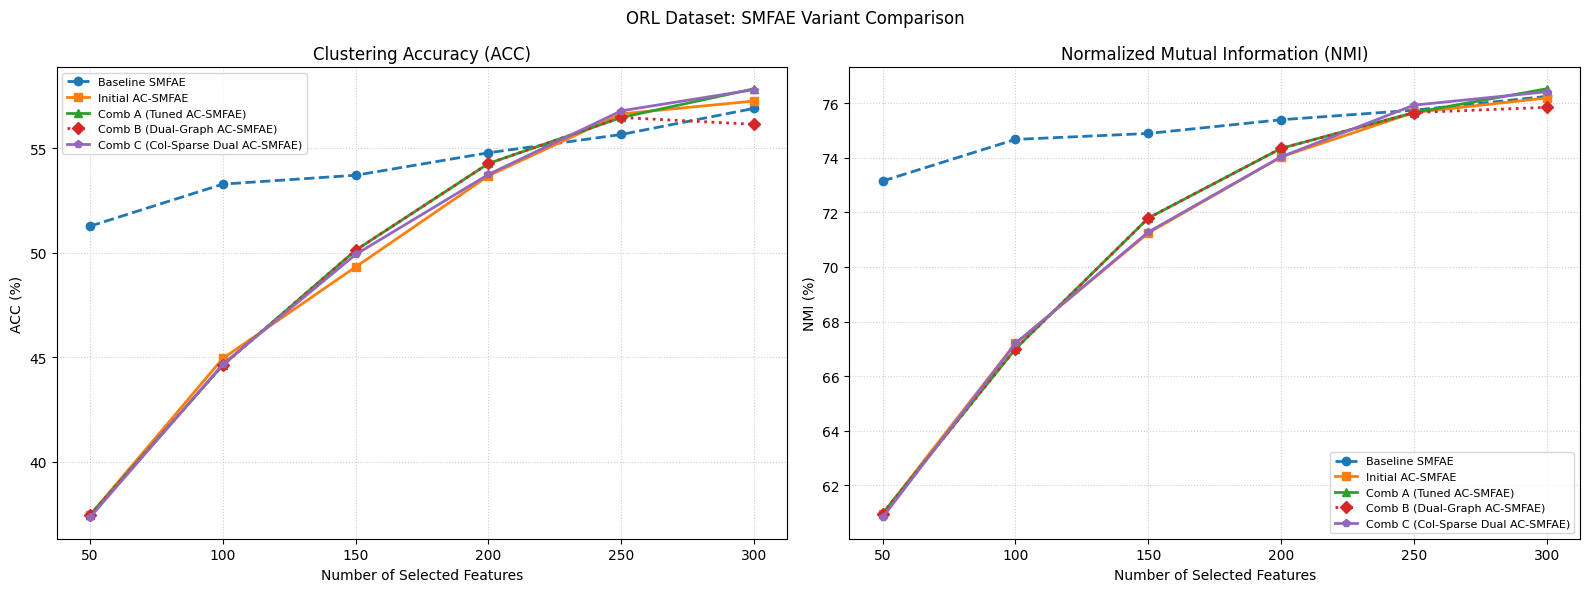

Comparison graph generated.


In [15]:

#generate png image of graph
import os
import pandas as pd
import matplotlib.pyplot as plt

# Load baseline results from the existing CSV
csv_path = os.path.join("..", "reports", "results", "accuracy_nmi.csv")

if not os.path.exists(csv_path):
    raise FileNotFoundError(f"CSV file not found: {csv_path}")

df = pd.read_csv(csv_path)

baseline_rows = df[
    (df["Dataset"].astype(str).str.upper() == "ORL")
    & (df["Method"].astype(str).str.strip().str.lower()
       .isin(["smfae", "baseline smfae"]))
]

if baseline_rows.empty:
    raise ValueError(
        "Baseline SMFAE results are not in the CSV. "
        "Check the actual baseline method name."
    )

baseline_results = {
    int(row["Num_Selected_Features"]): {
        "ACC_mean": row["ACC_Mean"],
        "NMI_mean": row["NMI_Mean"]
    }
    for _, row in baseline_rows.iterrows()
}

all_results = {
    "Baseline SMFAE": baseline_results,
    "Initial AC-SMFAE": results_ac_smfae,
    "Comb A (Tuned AC-SMFAE)": results_combination_a,
    "Comb B (Dual-Graph AC-SMFAE)": results_combination_b,
    "Comb C (Col-Sparse Dual AC-SMFAE)": results_combination_c,
}

styles = ["o--", "s-", "^-", "D:", "p-"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

for (method, results), style in zip(all_results.items(), styles):
    features = sorted(results.keys())
    acc = [results[r]["ACC_mean"] for r in features]
    nmi = [results[r]["NMI_mean"] for r in features]

    ax1.plot(features, acc, style, linewidth=2, label=method)
    ax2.plot(features, nmi, style, linewidth=2, label=method)

for ax, title, ylabel in [
    (ax1, "Clustering Accuracy (ACC)", "ACC (%)"),
    (ax2, "Normalized Mutual Information (NMI)", "NMI (%)")
]:
    ax.set_title(title)
    ax.set_xlabel("Number of Selected Features")
    ax.set_ylabel(ylabel)
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(fontsize=8)

fig.suptitle("ORL Dataset: SMFAE Variant Comparison")
fig.tight_layout()
plt.show()

print("Comparison graph generated.")


In [16]:
#save the image
import os

figures_dir = os.path.join("..", "reports", "figures")
os.makedirs(figures_dir, exist_ok=True)

graph_path = os.path.join(
    figures_dir, "ORL_All_Combinations_Comparison.png"
)

fig.savefig(graph_path, dpi=300, bbox_inches="tight")
print("Graph saved successfully:", os.path.abspath(graph_path))

plt.close(fig)


Graph saved successfully: d:\Projects\SMFS-AutoEncoder\reports\figures\ORL_All_Combinations_Comparison.png


In [17]:
# csv file 

import os
import pandas as pd

# Output file
results_dir = os.path.join("..", "reports", "results")
os.makedirs(results_dir, exist_ok=True)
csv_path = os.path.join(results_dir, "accuracy_nmi.csv")

# Experiment result dictionaries
all_results_csv = {
    "Initial AC-SMFAE": results_ac_smfae,
    "Comb A (Tuned AC-SMFAE)": results_combination_a,
    "Comb B (Dual-Graph AC-SMFAE)": results_combination_b,
    "Comb C (Col-Sparse Dual AC-SMFAE)": results_combination_c,
}

# Add baseline variable if already available
if "results_smfae" in globals():
    all_results_csv["Baseline SMFAE"] = results_smfae
elif "results_baseline" in globals():
    all_results_csv["Baseline SMFAE"] = results_baseline
else:
    # Try to read baseline results from the existing CSV
    if os.path.exists(csv_path):
        old_df = pd.read_csv(csv_path)
        baseline_rows = old_df[
            (old_df["Dataset"].astype(str).str.upper() == "ORL")
            & (old_df["Method"].astype(str).str.strip().str.lower()
               .isin(["smfae", "baseline smfae"]))
        ]

        if not baseline_rows.empty:
            all_results_csv["Baseline SMFAE"] = {
                int(row["Num_Selected_Features"]): {
                    "ACC_mean": row["ACC_Mean"],
                    "ACC_std": row["ACC_STD"],
                    "NMI_mean": row["NMI_Mean"],
                    "NMI_std": row["NMI_STD"]
                }
                for _, row in baseline_rows.iterrows()
            }

# Configuration from existing notebook variables
config = {
    "Dataset": "ORL",
    "Num_Samples": X.shape[1],
    "Num_Original_Features": X.shape[0],
    "Num_Classes": len(set(y)),
    "Hidden_Dimension": hidden_dim if "hidden_dim" in globals() else 200,
    "Alpha": alpha if "alpha" in globals() else 1e-4,
    "Beta": beta if "beta" in globals() else 1e-4,
    "Gamma": gamma if "gamma" in globals() else 5e-4,
    "Omega": omega if "omega" in globals() else 0.01,
    "Learning_Rate": learning_rate if "learning_rate" in globals() else 1e-4,
    "Epochs": epochs if "epochs" in globals() else 500,
    "KNN": k if "k" in globals() else 5,
    "Repetitions": n_repetitions if "n_repetitions" in globals() else 20,
}

# Build rows from actual experiment results
rows = []

for method, results in all_results_csv.items():
    for feature_count, result in sorted(results.items()):
        rows.append({
            "Method": method,
            **config,
            "Num_Features": feature_count,
            "Num_Selected_Features": feature_count,
            "ACC": result["ACC_mean"],
            "ACC_Mean": result["ACC_mean"],
            "ACC_STD": result.get("ACC_std", float("nan")),
            "NMI": result["NMI_mean"],
            "NMI_Mean": result["NMI_mean"],
            "NMI_STD": result.get("NMI_std", float("nan")),
        })

new_df = pd.DataFrame(rows)

if new_df.empty:
    raise ValueError("No experiment results found to save.")

# Preserve other datasets; replace only these ORL methods
if os.path.exists(csv_path):
    old_df = pd.read_csv(csv_path)

    if not {"Dataset", "Method"}.issubset(old_df.columns):
        raise ValueError("Existing CSV must contain Dataset and Method columns.")

    replace_methods = set(all_results_csv.keys())
    keep_rows = ~(
        old_df["Dataset"].astype(str).str.upper().eq("ORL")
        & old_df["Method"].isin(replace_methods)
    )
    old_df = old_df.loc[keep_rows]

    # Align columns in both dataframes
    all_columns = list(dict.fromkeys(list(old_df.columns) + list(new_df.columns)))
    old_df = old_df.reindex(columns=all_columns)
    new_df = new_df.reindex(columns=all_columns)
    final_df = pd.concat([old_df, new_df], ignore_index=True)
else:
    final_df = new_df

final_df.to_csv(csv_path, index=False)

print("CSV saved successfully:", os.path.abspath(csv_path))
print("New experiment rows:", len(new_df))
print("Total CSV rows:", len(final_df))
print("Methods saved:", list(all_results_csv.keys()))


CSV saved successfully: d:\Projects\SMFS-AutoEncoder\reports\results\accuracy_nmi.csv
New experiment rows: 30
Total CSV rows: 60
Methods saved: ['Initial AC-SMFAE', 'Comb A (Tuned AC-SMFAE)', 'Comb B (Dual-Graph AC-SMFAE)', 'Comb C (Col-Sparse Dual AC-SMFAE)', 'Baseline SMFAE']


## Findings

- **Baseline SMFAE:** Successfully reproduced on the ORL dataset (\(n=400, d=1024, K=40\)).
  - ACC: 56.90%
  - NMI: 76.25%

- **Proposed Model (AC-SMFAE):**
  - Added a Contractive Autoencoder to reduce noise effects.
  - Added an Adaptive Dynamic Graph to update data relationships.
  - Added a Feature Graph to learn feature relationships.
  - Used the \(L_{2,1}\) norm to select important features.

- **Improved Results:**
  - Combination A: ACC = 57.84%, NMI = 76.52%.
  - Combination C: ACC = 57.80%, NMI = 76.42%.

- **Loss Reduction:**
  - Initial loss: 14.2 million.
  - Final loss: 29,204.93.